# 02 · Grouped logistic regression: who is readmitted, and is the deprivation gap closing?

**Data:** 330 real NHS cells (deprivation quintile x age band x sex x year, 2014/15 to 2024/25),
each with readmissions out of discharges: 64.7 million discharges in total.

**Model:** binomial logistic regression on grouped data,

$$\text{readmissions}_c \sim \text{Binomial}(n_c, p_c), \qquad \log\frac{p_c}{1-p_c} = x_c^\top\beta .$$

Fitting to the cell counts gives exactly the same estimates as fitting to 64.7 million
patient rows with the same covariates: the cell totals are *sufficient statistics*.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from nhsread import viz
from nhsread.config import CELLS_FILE, YEARS
from nhsread.models import grouped as G
from nhsread.models.logit_scratch import fit_logit

viz.set_style()
pd.set_option("display.width", 140)
cells = pd.read_parquet(CELLS_FILE)
d = G.prepare(cells)
print(f"{len(d)} cells, {d['den'].sum():,} discharges, overall rate {d['num'].sum() / d['den'].sum():.2%}")

330 cells, 64,665,775 discharges, overall rate 14.07%


## 1. Our own IRLS implementation matches statsmodels
Before trusting a library, check it against first principles. `fit_logit` is Newton-Raphson /
IRLS written in NumPy (see `src/nhsread/models/logit_scratch.py`).

In [2]:
from patsy import dmatrices

y, X = dmatrices("num ~ C(imd_c) + age + sex", d, return_type="dataframe")
mine = fit_logit(X.to_numpy(), d["num"].to_numpy(), n=d["den"].to_numpy(), names=list(X.columns))
ref = G.fit(d, "C(imd_c) + age + sex")
pd.DataFrame({"scratch coef": mine.params, "statsmodels coef": ref.params.to_numpy(),
              "scratch se": mine.bse, "statsmodels se": ref.bse.to_numpy()}, index=X.columns).round(6)

,scratch coef,statsmodels coef,scratch se,statsmodels se
Intercept,-1.822546,-1.822546,0.000821,0.000821
C(imd_c)[T.2],-0.076562,-0.076562,0.001045,0.001045
C(imd_c)[T.3],-0.144309,-0.144309,0.001079,0.001079
C(imd_c)[T.4],-0.195584,-0.195584,0.001114,0.001114
C(imd_c)[T.5],-0.242097,-0.242097,0.001159,0.001159
age[T.<16],-0.061581,-0.061581,0.001119,0.001119
age[T.75+],0.425990,0.425990,0.000813,0.000813
sex[T.Male],0.049329,0.049329,0.000722,0.000722


In [3]:
print(f"iterations to converge: {mine.n_iter}; max |coef difference| = {np.max(np.abs(mine.params - ref.params.to_numpy())):.1e}")
print(f"deviance: scratch {mine.deviance:,.1f} vs statsmodels {ref.deviance:,.1f}")

iterations to converge: 5; max |coef difference| = 1.8e-15
deviance: scratch 54,337.0 vs statsmodels 54,337.0


## 2. Building the model step by step

Each step adds one idea. We compare by deviance, AIC and, because these data are over-dispersed
(section 3), by a **quasi-likelihood F-test** that scales the deviance change by the dispersion
of the larger model.

In [4]:
ladder = {
    "M0 intercept": "1",
    "M1 + age + sex": "age + sex",
    "M2 + deprivation": "age + sex + C(imd_c)",
    "M3 + year": "age + sex + C(imd_c) + C(year)",
    "M4 + deprivation x age": "age + sex + C(imd_c) * age + C(year)",
    "M5 + age x sex": "C(imd_c) * age + age * sex + C(year)",
    "M6 + year x age": "C(imd_c) * age + age * sex + C(year) * age",
}
fits = {k: G.fit(d, f) for k, f in ladder.items()}
rows, prev = [], None
for k, r in fits.items():
    row = {"model": k, "params": int(r.df_model + 1), "deviance": r.deviance, "resid df": int(r.df_resid),
           "dispersion": G.dispersion(r), "AIC": r.aic}
    if prev is not None:
        f, df1, df2, p = G.quasi_f_test(prev, r)
        row.update({"quasi F": f, "F p-value": p})
    rows.append(row)
    prev = r
ladder_tbl = pd.DataFrame(rows).set_index("model")
ladder_tbl.style.format({"deviance": "{:,.0f}", "dispersion": "{:.1f}", "AIC": "{:,.0f}", "quasi F": "{:.1f}",
                         "F p-value": "{:.2g}"})

,params,deviance,resid df,dispersion,AIC,quasi F,F p-value
model,,,,,,,
M0 intercept,1,"386,363",329,1207.0,"390,224",nan,nan
M1 + age + sex,4,"112,102",326,340.2,"115,969",268.7,9e-88
M2 + deprivation,8,"54,337",322,167.5,"58,212",86.2,1e-49
M3 + year,18,"22,060",312,70.3,"25,954",45.9,1.7e-55
M4 + deprivation x age,26,"16,968",304,55.5,"20,879",11.5,3.2e-14
M5 + age x sex,28,"15,111",302,49.8,"19,026",18.6,2.4e-08
M6 + year x age,48,"4,513",282,16.1,"8,468",33.0,4.9e-62


Every step improves the fit significantly, even after allowing for over-dispersion:

* **Deprivation** is a large effect on top of age and sex.
* **Year** removes a lot of deviance: the national rate drifted up over the decade.
* **Deprivation x age**: the gradient really does differ by age (notebook 01).
* **Year x age** is the biggest late gain: the upward drift was not the same for every age group.

We use **M5** as the *interpretation* model (clean deprivation and age effects with a common year
effect) and keep M6 as a check that the deprivation conclusions do not depend on it.

## 3. Over-dispersion: why the textbook standard errors are wrong here

For a correct binomial model, Pearson chi-square / residual df should be about 1.
Here it is far larger even for the richest model: real cells are aggregates of very
different places and hospitals, so they vary much more than binomial sampling allows.

The fix is **quasi-binomial** inference: keep the same coefficients but multiply the variance
by the dispersion $\hat\phi$ (standard errors grow by $\sqrt{\hat\phi}$).

> **Pitfall found while building this:** with a two-column (successes, failures) response,
> `statsmodels` `fit(scale="X2")` estimates the dispersion on the *proportion* scale and returns
> a tiny value, which shrinks the standard errors instead of inflating them. `grouped.fit`
> computes Pearson chi-square / df itself and refits with that scale (there is a unit test).

In [5]:
m5 = fits["M5 + age x sex"]
q5 = G.fit(d, ladder["M5 + age x sex"], scale="X2")
phi = G.dispersion(m5)
cmp = pd.DataFrame({"binomial SE": m5.bse, "quasi SE": q5.bse, "ratio": q5.bse / m5.bse}).iloc[:6]
print(f"dispersion phi = {phi:.1f}  ->  SEs inflate by sqrt(phi) = {np.sqrt(phi):.2f}")
cmp.round(5)

dispersion phi = 49.8  ->  SEs inflate by sqrt(phi) = 7.06


,binomial SE,quasi SE,ratio
Intercept,0.00156,0.01104,7.05896
C(imd_c)[T.2],0.00133,0.00939,7.05896
C(imd_c)[T.3],0.00140,0.00991,7.05896
C(imd_c)[T.4],0.00148,0.01042,7.05896
C(imd_c)[T.5],0.00157,0.01106,7.05896
age[T.<16],0.00239,0.01689,7.05896


With 64.7 million discharges, the ordinary binomial errors are microscopic and every effect looks
"certain". The quasi-binomial errors are about 7 times bigger, which is still small, because the
data really are huge, but honest.

## 4. Interpreting the coefficients

A logistic coefficient is a change in **log-odds**; $e^\beta$ is an **odds ratio** (OR).
With a 14% outcome, odds ratios overstate relative risks a little (OR 1.20 is roughly RR 1.17),
so for communication we also report **average marginal effects** in percentage points.

In [6]:
ors = G.odds_ratio_table(q5)
ors = ors.loc[[i for i in ors.index if not i.startswith("C(year)")]]
ors[["odds_ratio", "or_lo", "or_hi", "p"]].style.format({"odds_ratio": "{:.3f}", "or_lo": "{:.3f}", "or_hi": "{:.3f}",
                                                         "p": "{:.1e}"})

,odds_ratio,or_lo,or_hi,p
Intercept,0.146,0.143,0.149,0.0e+00
C(imd_c)[T.2],0.917,0.901,0.934,4.4e-20
C(imd_c)[T.3],0.847,0.831,0.864,5.0e-63
C(imd_c)[T.4],0.795,0.779,0.812,6.0e-107
C(imd_c)[T.5],0.754,0.738,0.770,4.1e-144
age[T.<16],0.893,0.864,0.923,2.2e-11
age[T.75+],1.475,1.437,1.514,7.1e-190
sex[T.Male],1.045,1.031,1.058,9.1e-11
C(imd_c)[T.2]:age[T.<16],1.039,0.994,1.086,8.7e-02
C(imd_c)[T.3]:age[T.<16],1.131,1.081,1.184,1.4e-07


Reference category: most deprived quintile (1), age 16-74, female, 2014/15. Because deprivation
interacts with age, the `C(imd_c)[T.k]` rows are the deprivation effects **for 16-74 year olds**;
the interaction rows say how much flatter (or steeper) the gradient is for children and 75+.

M5 assumes one deprivation effect for the whole decade. Section 6 shows the gap has narrowed, so
for *current* effects we refit the same structure on 2024/25 cells only, then average the
predicted change over that year's discharges.

In [7]:
lat = d[d["year"] == "2024/25"].copy()
m_lat = G.fit(lat, "C(imd_c) * age + age * sex")
ame = {
    "most (1) vs least (5) deprived": G.average_marginal_effect(m_lat, lat, "imd_c", (5, 1)),
    "age 75+ vs 16-74": G.average_marginal_effect(m_lat, lat, "age", ("16-74", "75+")),
    "male vs female": G.average_marginal_effect(m_lat, lat, "sex", ("Female", "Male")),
    "(decade-average M5) most vs least deprived": G.average_marginal_effect(m5, lat, "imd_c", (5, 1)),
}
ame_s = pd.Series(ame, name="average marginal effect, percentage points (2024/25 discharges)")
ame_s.round(2).to_frame()

,"average marginal effect, percentage points (2024/25 discharges)"
most (1) vs least (5) deprived,2.44
age 75+ vs 16-74,4.42
male vs female,0.53
(decade-average M5) most vs least deprived,3.06


In [8]:
extra = ame["most (1) vs least (5) deprived"] / 100 * lat["den"].sum()
print(f"implied extra readmissions if every 2024/25 discharge had most- rather than least-deprived risk: {extra:,.0f}")

implied extra readmissions if every 2024/25 discharge had most- rather than least-deprived risk: 156,019


For the 2024/25 discharge population, moving everyone from the least to the most deprived
quintile adds about **2.4 percentage points**, roughly 156,000 extra readmissions a year on
6.4 million discharges. Being 75+ rather than 16-74 adds about 4.4 points.

Two lessons sit in this table:

* The adjusted deprivation effect (2.4 points) is **bigger than the crude gap** (1.7 points in
  notebook 01) because discharges from deprived areas are younger on average, and younger
  patients have lower risk. Age partly masks the inequality: classic confounding.
* The decade-average model says 3.1 points. Using a pooled model for a *current* estimate when the
  effect is changing would overstate today's gap.

## 5. The fitted interaction, as a picture

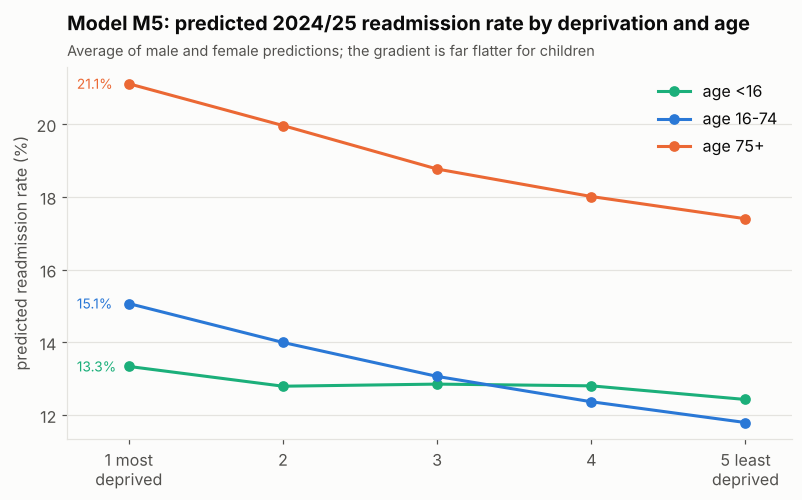

In [9]:
pred = G.predicted_grid(m5, ["2024/25"], {"2024/25": 2024})
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for a, col in viz.AGE_COLOURS.items():
    s = pred[pred["age"] == a].groupby("imd")["pred_pct"].mean()
    ax.plot(s.index, s.values, marker="o", color=col, label=f"age {a}")
    ax.annotate(f"{s.iloc[0]:.1f}%", (1, s.iloc[0]), xytext=(-34, 0), textcoords="offset points", va="center",
                fontsize=9, color=col)
ax.set_xticks(range(1, 6), ["1 most\ndeprived", "2", "3", "4", "5 least\ndeprived"])
ax.set_xlim(0.6, 5.3)
ax.set_ylabel("predicted readmission rate (%)")
ax.legend(loc="upper right")
ax.set_title("Model M5: predicted 2024/25 readmission rate by deprivation and age")
viz.subtitle(ax, "Average of male and female predictions; the gradient is far flatter for children")
viz.save(fig, "02_interaction")
fig

## 6. Is the deprivation gap closing?

UK public-health reporting summarises inequality with the **Slope Index of Inequality (SII)**:
the modelled absolute gap (percentage points) between the most and least deprived ends of the
population, and the **Relative Index of Inequality (RII)**: the same thing as a ratio, here as an
odds ratio from a logistic fit on the population *ridit* (cumulative share) of deprivation.

In [10]:
ineq = pd.DataFrame({y: G.inequality_indices(cells[cells["year"] == y]) for y in YEARS}).T
ineq[["rate_most", "rate_least", "gap_pp", "sii_pp", "rii_or"]].round(3)

,rate_most,rate_least,gap_pp,sii_pp,rii_or
2014/15,14.002,11.224,2.778,3.554,1.381
2015/16,14.429,11.590,2.839,3.568,1.371
2016/17,14.338,11.995,2.342,2.997,1.301
2017/18,14.820,12.501,2.319,2.922,1.282
2018/19,15.354,13.046,2.308,2.823,1.261
2019/20,15.371,13.310,2.061,2.578,1.234
2020/21,16.555,14.328,2.227,2.817,1.241
2021/22,15.227,13.564,1.663,2.160,1.192
2022/23,15.090,13.483,1.607,2.114,1.189
2023/24,15.641,13.917,1.724,2.115,1.182


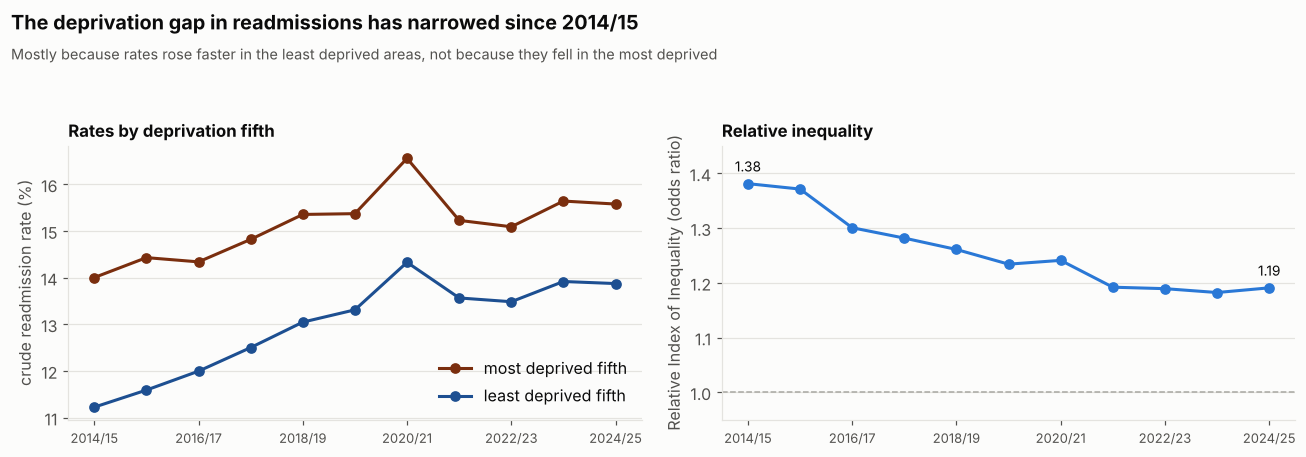

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(YEARS))
ax = axes[0]
ax.plot(x, ineq["rate_most"], marker="o", color=viz.IMD_COLOURS[1], label="most deprived fifth")
ax.plot(x, ineq["rate_least"], marker="o", color=viz.IMD_COLOURS[5], label="least deprived fifth")
ax.set_xticks(x[::2], [YEARS[i] for i in x[::2]], fontsize=8.5)
ax.set_ylabel("crude readmission rate (%)")
ax.legend(loc="lower right")
ax.set_title("Rates by deprivation fifth", fontsize=11, pad=6)
ax = axes[1]
ax.plot(x, ineq["rii_or"], marker="o", color=viz.BLUE)
ax.set_xticks(x[::2], [YEARS[i] for i in x[::2]], fontsize=8.5)
ax.set_ylabel("Relative Index of Inequality (odds ratio)")
ax.axhline(1, color=viz.GREY, lw=1, ls="--")
ax.set_ylim(0.95, 1.45)
ax.set_title("Relative inequality", fontsize=11, pad=6)
for i in [0, len(YEARS) - 1]:
    ax.annotate(f"{ineq['rii_or'].iloc[i]:.2f}", (i, ineq["rii_or"].iloc[i]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9)
viz.fig_title(fig, "The deprivation gap in readmissions has narrowed since 2014/15",
              "Mostly because rates rose faster in the least deprived areas, not because they fell in the most deprived")
viz.save(fig, "02_inequality_trend")
fig

### A formal test of the narrowing
Replace the deprivation categories with a linear deprivation score (1 = least ... 5 = most
deprived) and let its slope change over time. The `deprived:t` coefficient is the yearly change
in the log-odds gradient; quasi-binomial errors keep the test honest.

In [12]:
trend = G.fit(d, "deprived + deprived:t + deprived:age + age * sex + C(year)", scale="X2")
tt = G.odds_ratio_table(trend).loc[["deprived", "deprived:t"]]
tt[["coef", "se", "p"]].style.format({"coef": "{:.4f}", "se": "{:.4f}", "p": "{:.2g}"})

,coef,se,p
deprived,0.0870,0.0037,3.3e-119
deprived:t,-0.0028,0.0006,5.5e-07


In [13]:
b0, b1 = trend.params["deprived"], trend.params["deprived:t"]
print(f"odds ratio per deprivation step (16-74s): 2014/15 {np.exp(b0):.3f} -> 2024/25 {np.exp(b0 + 10 * b1):.3f}")

odds ratio per deprivation step (16-74s): 2014/15 1.091 -> 2024/25 1.061


In [14]:
trend6 = G.fit(d, "deprived + deprived:t + deprived:age + age * sex + C(year) * age", scale="X2")
r6 = G.odds_ratio_table(trend6).loc["deprived:t"]
print(f"robustness (year x age effects as in M6): deprived:t = {r6['coef']:.4f} (quasi SE {r6['se']:.4f}, p = {r6['p']:.1g})")

robustness (year x age effects as in M6): deprived:t = -0.0038 (quasi SE 0.0003, p = 1e-44)


The gradient shrinks year on year by about five quasi-binomial standard errors' worth, and the
result survives letting every age band have its own year effects (as in M6), so it is not an
artefact of how the time trend is modelled.

**Caution on interpretation.** This is an *association* in aggregated data. A narrowing gap could
reflect changes in who is admitted (for example, more short-stay emergency care in less deprived
areas), coding practice, or genuine improvement. The data cannot separate these: an ecological
analysis says where to look, not why.

## 7. Where does the model fit badly?
Pearson residuals by cell (from M5). Large values show the cells the model cannot explain.

In [15]:
d["fitted"] = m5.fittedvalues
d["pearson"] = m5.resid_pearson
worst = d.reindex(d["pearson"].abs().sort_values(ascending=False).index).head(8)
worst[["year", "imd", "age", "sex", "rate", "fitted", "pearson"]].round(4)

,year,imd,age,sex,rate,fitted,pearson
264,2022/23,5,16-74,Female,0.1225,0.1118,18.3280
185,2020/21,1,<16,Male,0.1169,0.1387,-17.6920
24,2014/15,5,16-74,Female,0.0897,0.0990,-16.7334
288,2023/24,4,16-74,Female,0.1312,0.1225,16.3481
324,2024/25,5,16-74,Female,0.1244,0.1157,15.7792
12,2014/15,3,16-74,Female,0.1019,0.1099,-15.4973
272,2023/24,1,75+,Female,0.1898,0.2057,-15.1590
18,2014/15,4,16-74,Female,0.0961,0.1039,-14.7195


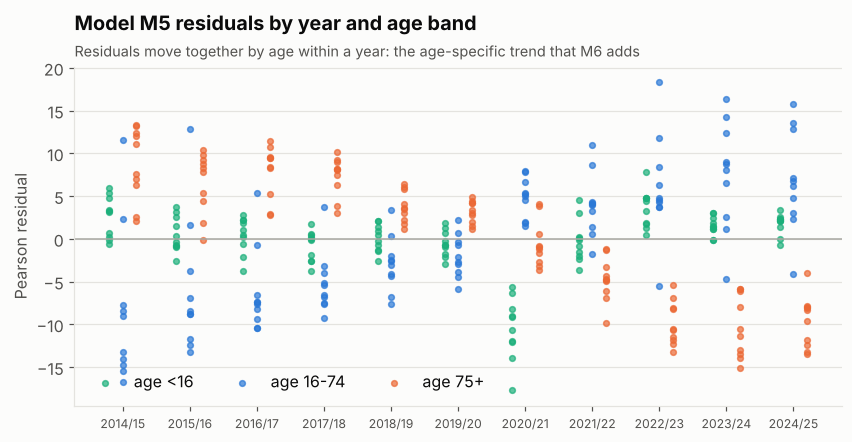

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
for a, col in viz.AGE_COLOURS.items():
    s = d[d["age"] == a]
    ax.scatter(s["year_start"] + {"<16": -0.2, "16-74": 0, "75+": 0.2}[a], s["pearson"], s=14, color=col,
               alpha=0.7, label=f"age {a}")
ax.axhline(0, color=viz.GREY, lw=1)
ax.set_xticks(range(2014, 2025), YEARS, fontsize=8)
ax.set_ylabel("Pearson residual")
ax.legend(ncol=3, loc="lower left")
ax.set_title("Model M5 residuals by year and age band")
viz.subtitle(ax, "Residuals move together by age within a year: the age-specific trend that M6 adds")
viz.save(fig, "02_residuals")
fig

The residuals cluster by age within years: the national drift was different for children,
working-age adults and the over-75s. That is exactly what the `year x age` term in M6 captures,
and why its deviance gain was so large.

**Takeaways**

* Grouped logistic regression on 330 real cells reproduces patient-level estimates at a fraction
  of the cost, and our from-scratch IRLS matches statsmodels to machine precision.
* Deprivation, age, sex and year all matter; deprivation matters **more for adults than children**.
* The data are heavily over-dispersed, so binomial standard errors overstate certainty about
  7-fold; quasi-binomial inference fixes this (and exposed a statsmodels pitfall).
* The deprivation gap in readmissions has **narrowed** since 2014/15 (RII 1.38 to 1.19),
  mainly because rates rose faster in the least deprived areas.